# 06 - Compléments de modélisation : noyaux SVM, élagage, impact de K, ablation, tableau unifié

Ce notebook complète les notebooks 03 (six modèles) et 04 (AdaBoost, XGBoost, Soft Voting) pour répondre aux critères **1.3, 1.4 et 1.5** du barème :

- validation croisée **stratifiée à 6 plis** (K ≥ 5 exigé), identique au reste du projet, avec le **F1 macro** comme critère d'optimisation (le F1 de la classe 1 seule est gonflé par le déséquilibre 82/18) ;
- **SVM** avec comparaison des noyaux linéaire, RBF et polynomial ;
- **élagage par coût-complexité** (`ccp_alpha`) pour l'arbre de décision ;
- étude de l'impact de **K** et de la **métrique de distance** pour K-NN ;
- **Naïve Bayes** avec lissage de Laplace (`alpha`) sur des variables non négatives (MinMax au lieu de « clipper » les valeurs négatives) ;
- **tableau unifié** : tous les modèles, y compris AdaBoost, XGBoost et Soft Voting du notebook 04, avec F1 de chaque classe, F1 macro, ROC-AUC, PR-AUC, matrices de confusion et courbes ROC ;
- **ablation** pour mesurer le poids de la variable `Rating` et du texte.

> **Mode rapide** : `DM_FAST=1` (variable d'environnement) réduit les données et les grilles pour tester le notebook en quelques minutes. En mode rapide, rien n'est écrit dans `models/`.

## 1. Configuration

In [ ]:
import os, sys, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from ml_utils import (
    build_preprocessor, evaluate_model, evaluate_scores, get_cv, get_scores,
    load_clean_data, split_data, RANDOM_STATE, N_SPLITS,
)

FAST_MODE = os.environ.get("DM_FAST", "0") == "1"
SUB = "fast" if FAST_MODE else ""
FIG_DIR = ROOT / "docs" / "figures" / SUB
REPORT_DIR = ROOT / "reports" / SUB
MODELS_DIR = ROOT / "models"
for d in (FIG_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

SCORING = "f1_macro"   # classes déséquilibrées (82/18) : on optimise le F1 macro, pas l'accuracy
N_JOBS = -1
print(f"Racine du projet : {ROOT}")
print(f"Mode rapide      : {FAST_MODE}")

Racine du projet : /home/claude/work_v5
Mode rapide      : False


## 2. Données et prétraitement

On reprend **exactement** le découpage du notebook 02 (80/20 stratifié, `random_state=42`).
Le prétraitement est appris sur le train uniquement (pas de fuite de données).
Naïve Bayes multinomial exige des valeurs ≥ 0 : on lui fournit un second prétraitement avec `MinMaxScaler`.

*Remarque méthodologique* : comme dans les notebooks 03 et 04, le prétraitement (vocabulaire et IDF du TF-IDF) est appris sur **tout** le jeu d'entraînement avant la validation croisée.
La fuite vers les plis de validation est très faible (seul l'IDF est concerné) et identique pour tous les modèles : elle ne change pas leur classement. Le notebook 08 refait l'apprentissage du vocabulaire à chaque pli.

In [ ]:
df = load_clean_data()
X_train, X_test, y_train, y_test = split_data(df)

if FAST_MODE:  # sous-échantillon stratifié pour tester le code rapidement
    from sklearn.model_selection import train_test_split
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=3000, random_state=RANDOM_STATE, stratify=y_train)
    X_test, _, y_test, _ = train_test_split(X_test, y_test, train_size=1000, random_state=RANDOM_STATE, stratify=y_test)

prep = build_preprocessor("standard")
Xtr, Xte = prep.fit_transform(X_train), prep.transform(X_test)

prep_nb = build_preprocessor("minmax")
Xtr_nb, Xte_nb = prep_nb.fit_transform(X_train), prep_nb.transform(X_test)

cv = get_cv()   # StratifiedKFold(5, shuffle=True, random_state=42)
print("Train :", Xtr.shape, "| Test :", Xte.shape)
print("Répartition cible (train) :", y_train.value_counts(normalize=True).round(3).to_dict())
print("Validation croisée :", cv)

Train : (18772, 13035) | Test : (4693, 13035)
Répartition cible (train) : {1: 0.822, 0: 0.178}
Validation croisée : StratifiedKFold(n_splits=6, random_state=42, shuffle=True)


## 3. Outils d'expérimentation

`run_search` ajuste une recherche d'hyperparamètres (`GridSearchCV`, validation croisée stratifiée 6 plis),
mesure le temps, puis évalue le meilleur modèle sur le jeu de test avec **toutes** les métriques.
Le modèle est **choisi sur le score de validation croisée**, jamais sur le test.

In [ ]:
from sklearn.model_selection import GridSearchCV

REGISTRY = {}   # nom -> dict(model, Xte, prep, search, row)

def run_search(name, search, Xtr_, Xte_, prep_obj):
    t0 = time.time()
    search.fit(Xtr_, y_train)
    elapsed = time.time() - t0
    i = search.best_index_
    row = {
        "Modèle": name,
        "Meilleurs hyperparamètres": str(search.best_params_),
        "CV F1 macro (moy.)": search.cv_results_["mean_test_score"][i],
        "CV F1 macro (écart-type)": search.cv_results_["std_test_score"][i],
        "Temps (s)": elapsed,
    }
    row.update(evaluate_model(search.best_estimator_, Xte_, y_test))
    REGISTRY[name] = {"model": search.best_estimator_, "Xte": Xte_, "prep": prep_obj, "search": search, "row": row,
                      "y_pred": search.best_estimator_.predict(Xte_), "scores": get_scores(search.best_estimator_, Xte_)}
    print(f"{name:<28} CV F1 macro = {row['CV F1 macro (moy.)']:.4f} ± {row['CV F1 macro (écart-type)']:.4f}"
          f" | test F1 macro = {row['F1 macro']:.4f} | AUC = {row['ROC-AUC']:.4f} | {elapsed:.0f}s")
    return search

## 4. Baseline Zero-R

Classifieur naïf (classe majoritaire). Il fixe le plancher à battre : accuracy ≈ 0,82 mais F1 macro ≈ 0,45.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

zero_r = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
cv_scores = cross_val_score(DummyClassifier(strategy="most_frequent"), Xtr, y_train, cv=cv, scoring=SCORING)
row = {"Modèle": "Zero-R (baseline)", "Meilleurs hyperparamètres": "{'strategy': 'most_frequent'}",
       "CV F1 macro (moy.)": cv_scores.mean(), "CV F1 macro (écart-type)": cv_scores.std(), "Temps (s)": 0.0}
row.update(evaluate_model(zero_r, Xte, y_test))
REGISTRY["Zero-R (baseline)"] = {"model": zero_r, "Xte": Xte, "prep": prep, "search": None, "row": row,
                                 "y_pred": zero_r.predict(Xte), "scores": get_scores(zero_r, Xte)}
print(f"Zero-R : accuracy = {row['Accuracy']:.4f} | F1 macro = {row['F1 macro']:.4f}")

Zero-R : accuracy = 0.8223 | F1 macro = 0.4512


## 5. K-NN : impact de K et de la métrique de distance

On compare la distance euclidienne et la distance cosinus (naturelle pour des vecteurs TF-IDF), pour plusieurs valeurs de K.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_grid = {
    "n_neighbors": [5, 21] if FAST_MODE else [5, 11, 21, 41],
    "metric": ["euclidean", "cosine"],
    "weights": ["uniform", "distance"],
}
s_knn = run_search("K-NN", GridSearchCV(KNeighborsClassifier(algorithm="brute"), knn_grid, cv=cv, scoring=SCORING, n_jobs=N_JOBS),
                   Xtr, Xte, prep)

K-NN                         CV F1 macro = 0.8976 ± 0.0034 | test F1 macro = 0.8853 | AUC = 0.9692 | 49s


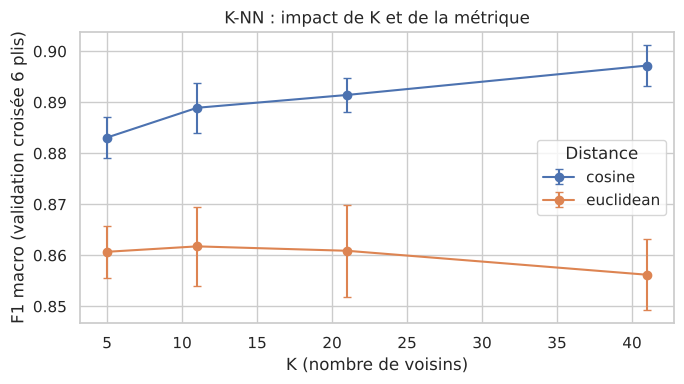

In [ ]:
res = pd.DataFrame(s_knn.cv_results_)
res = res[res["param_weights"] == "uniform"]
fig, ax = plt.subplots(figsize=(7, 4))
for metric, g in res.groupby("param_metric"):
    g = g.sort_values("param_n_neighbors")
    ax.errorbar(g["param_n_neighbors"].astype(int), g["mean_test_score"], yerr=g["std_test_score"], marker="o", capsize=3, label=metric)
ax.set_xlabel("K (nombre de voisins)"); ax.set_ylabel("F1 macro (validation croisée 6 plis)")
ax.set_title("K-NN : impact de K et de la métrique"); ax.legend(title="Distance")
fig.tight_layout(); fig.savefig(FIG_DIR / "knn_k_curve.png", dpi=200); plt.show()

## 6. Arbre de décision : critère, profondeur, puis élagage par coût-complexité

Deux étapes : (1) choix du critère (Gini / entropie) et de la profondeur maximale ;
(2) **élagage post-hoc** : on balaie `ccp_alpha` sur l'arbre retenu. Plus `ccp_alpha` est grand, plus l'arbre est élagué.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_grid = {"criterion": ["gini", "entropy"], "max_depth": [5, 20] if FAST_MODE else [5, 10, 20, None]}
s_dt1 = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid, cv=cv, scoring=SCORING, n_jobs=N_JOBS).fit(Xtr, y_train)
print("Étape 1 :", s_dt1.best_params_, f"-> CV F1 macro = {s_dt1.best_score_:.4f}")

base_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **s_dt1.best_params_)
path = base_tree.cost_complexity_pruning_path(Xtr, y_train)
alphas = path.ccp_alphas[:-1]  # le dernier alpha élague tout l'arbre (une seule feuille)
candidates = sorted(set([0.0] + list(np.quantile(alphas, np.linspace(0.3, 0.98, 6 if FAST_MODE else 9)))))
print(f"{len(alphas)} valeurs de ccp_alpha possibles, {len(candidates)} testées.")

Étape 1 : {'criterion': 'gini', 'max_depth': 5} -> CV F1 macro = 0.9016


19 valeurs de ccp_alpha possibles, 10 testées.


Arbre de décision (élagué)   CV F1 macro = 0.9037 ± 0.0052 | test F1 macro = 0.8918 | AUC = 0.9551 | 11s


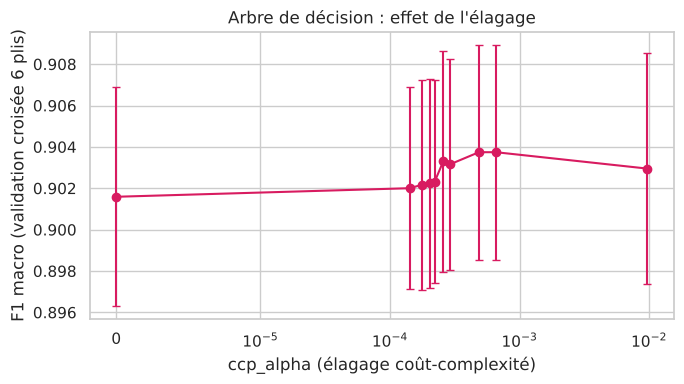

Nombre de feuilles de l'arbre final : 6


In [ ]:
s_dt = run_search("Arbre de décision (élagué)",
                  GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE, **s_dt1.best_params_),
                               {"ccp_alpha": candidates}, cv=cv, scoring=SCORING, n_jobs=N_JOBS),
                  Xtr, Xte, prep)

res = pd.DataFrame(s_dt.cv_results_).sort_values("param_ccp_alpha")
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(res["param_ccp_alpha"].astype(float), res["mean_test_score"], yerr=res["std_test_score"], marker="o", capsize=3, color="#D81B60")
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlabel("ccp_alpha (élagage coût-complexité)"); ax.set_ylabel("F1 macro (validation croisée 6 plis)")
ax.set_title("Arbre de décision : effet de l'élagage")
fig.tight_layout(); fig.savefig(FIG_DIR / "tree_pruning_curve.png", dpi=200); plt.show()
print("Nombre de feuilles de l'arbre final :", REGISTRY["Arbre de décision (élagué)"]["model"].get_n_leaves())

## 7. Random Forest

Recherche aléatoire (`RandomizedSearchCV`, autorisée par le cahier des charges) : l'espace est trop grand pour une grille exhaustive.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_space = {
    "n_estimators": [50, 100] if FAST_MODE else [100, 200],
    "max_depth": [None, 20] if FAST_MODE else [None, 30],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
    "class_weight": [None, "balanced"],
}
_ = run_search("Random Forest",
           RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), rf_space,
                              n_iter=3 if FAST_MODE else 5, cv=cv, scoring=SCORING, n_jobs=N_JOBS, random_state=RANDOM_STATE),
           Xtr, Xte, prep)

Random Forest                CV F1 macro = 0.8965 ± 0.0045 | test F1 macro = 0.8901 | AUC = 0.9689 | 200s


## 8. Naïve Bayes multinomial avec lissage de Laplace

`alpha` est le paramètre de lissage de Laplace (`alpha=1` = lissage de Laplace classique, `alpha<1` = lissage de Lidstone).
`GaussianNB` n'est pas retenu : il exige une matrice dense (13 035 colonnes × 18 772 lignes ≈ 2 Go) et suppose des variables gaussiennes, hypothèse peu adaptée à des fréquences TF-IDF.

In [ ]:
from sklearn.naive_bayes import MultinomialNB

_ = run_search("Naïve Bayes multinomial",
           GridSearchCV(MultinomialNB(), {"alpha": [0.01, 0.1, 0.5, 1.0, 2.0], "fit_prior": [True, False]},
                        cv=cv, scoring=SCORING, n_jobs=N_JOBS),
           Xtr_nb, Xte_nb, prep_nb)

Naïve Bayes multinomial      CV F1 macro = 0.8478 ± 0.0032 | test F1 macro = 0.8524 | AUC = 0.9516 | 1s


## 9. SVM : noyaux linéaire, RBF et polynomial

- `LinearSVC` (plus rapide, adapté aux espaces de grande dimension creux) avec `class_weight` ;
- `SVC` avec les trois noyaux demandés, en réglant `C`, `gamma` et `degree`.

In [ ]:
from sklearn.svm import LinearSVC, SVC

_ = run_search("SVM linéaire (LinearSVC)",
           GridSearchCV(LinearSVC(random_state=RANDOM_STATE, max_iter=5000),
                        {"C": [0.1, 1.0] if FAST_MODE else [0.1, 1.0, 10.0], "class_weight": [None, "balanced"]},
                        cv=cv, scoring=SCORING, n_jobs=N_JOBS),
           Xtr, Xte, prep)

SVM linéaire (LinearSVC)     CV F1 macro = 0.9046 ± 0.0056 | test F1 macro = 0.8927 | AUC = 0.9774 | 8s


SVM à noyaux (SVC)           CV F1 macro = 0.9041 ± 0.0062 | test F1 macro = 0.8920 | AUC = 0.9767 | 710s


,Noyau,CV F1 macro,écart-type,Meilleurs paramètres
0,linear,0.9041,0.0062,"{'C': 0.1, 'kernel': 'linear'}"
6,poly,0.9022,0.0043,"{'C': 1.0, 'degree': 2, 'gamma': 'scale', 'ker..."
2,rbf,0.9028,0.0053,"{'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}"


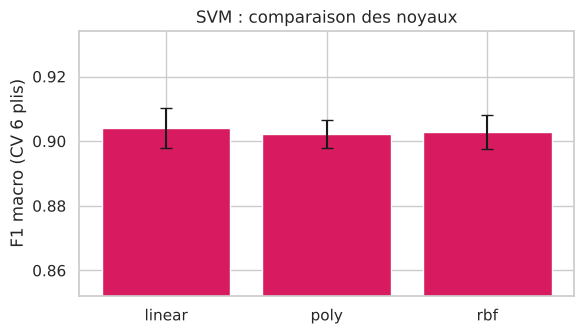

In [ ]:
svc_grid = [
    {"kernel": ["linear"], "C": [1.0] if FAST_MODE else [0.1, 1.0]},
    {"kernel": ["rbf"], "C": [1.0] if FAST_MODE else [1.0, 10.0], "gamma": ["scale"] if FAST_MODE else ["scale", 0.5]},
    {"kernel": ["poly"], "C": [1.0], "degree": [2] if FAST_MODE else [2, 3], "gamma": ["scale"]},
]
s_svc = run_search("SVM à noyaux (SVC)",
                   GridSearchCV(SVC(cache_size=1000, random_state=RANDOM_STATE), svc_grid, cv=cv, scoring=SCORING, n_jobs=N_JOBS),
                   Xtr, Xte, prep)

res = pd.DataFrame(s_svc.cv_results_)
best_per_kernel = res.loc[res.groupby("param_kernel")["mean_test_score"].idxmax(), ["param_kernel", "mean_test_score", "std_test_score", "params"]]
display(best_per_kernel.rename(columns={"param_kernel": "Noyau", "mean_test_score": "CV F1 macro", "std_test_score": "écart-type", "params": "Meilleurs paramètres"}).round(4))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(best_per_kernel["param_kernel"], best_per_kernel["mean_test_score"], yerr=best_per_kernel["std_test_score"], color="#D81B60", capsize=4)
ax.set_ylabel("F1 macro (CV 6 plis)"); ax.set_title("SVM : comparaison des noyaux")
ax.set_ylim(max(0, best_per_kernel["mean_test_score"].min() - 0.05), min(1, best_per_kernel["mean_test_score"].max() + 0.03))
fig.tight_layout(); fig.savefig(FIG_DIR / "svm_kernels.png", dpi=200); plt.show()

## 10. Modèles d'ensemble du notebook 04 (AdaBoost, XGBoost, Soft Voting)

Ces trois modèles ont déjà été entraînés et réglés dans le notebook 04 (`GridSearchCV`, 6 plis, critère F1 de la classe 1).
On **ne les réentraîne pas** : on relit leurs scores sur le jeu de test (`models/ensemble_test_scores.csv`) pour les mettre dans le même tableau,
avec les mêmes métriques. Leur validation croisée n'est pas comparable à celle de ce notebook (autre critère), elle n'est donc pas reportée ici.

In [ ]:
ens_path = MODELS_DIR / "ensemble_test_scores.csv"
if FAST_MODE or not ens_path.exists():
    print("Modèles d'ensemble non intégrés (mode rapide ou fichier absent).")
else:
    ens = pd.read_csv(ens_path).set_index("row_id").loc[y_test.index]
    assert (ens["y_true"].values == y_test.values).all(), "Les lignes du test ne correspondent pas au notebook 04"
    for name in ["AdaBoost", "XGBoost", "Soft Voting (NB + RF)"]:
        sc = ens[name].values
        yp = (sc >= 0.5).astype(int)
        row = {"Modèle": name, "Meilleurs hyperparamètres": "voir notebook 04",
               "CV F1 macro (moy.)": np.nan, "CV F1 macro (écart-type)": np.nan, "Temps (s)": np.nan}
        row.update(evaluate_scores(y_test, yp, sc))
        REGISTRY[name] = {"model": None, "Xte": None, "prep": None, "search": None, "row": row, "y_pred": yp, "scores": sc}
        print(f"{name:<24} F1 macro = {row['F1 macro']:.4f} | F1 (0) = {row['F1 (0)']:.4f} | AUC = {row['ROC-AUC']:.4f}")

AdaBoost                 F1 macro = 0.8920 | F1 (0) = 0.8247 | AUC = 0.9743
XGBoost                  F1 macro = 0.8892 | F1 (0) = 0.8187 | AUC = 0.9733
Soft Voting (NB + RF)    F1 macro = 0.8870 | F1 (0) = 0.8125 | AUC = 0.9737


## 11. Tableau comparatif multicritère (critère 1.5)

Tri sur le **score de validation croisée** (et non sur le test). Le F1 de la classe 1 est écrasé par le déséquilibre :
on lit surtout **F1 (0)**, **F1 macro** et **ROC-AUC / PR-AUC**.

In [ ]:
results = pd.DataFrame([v["row"] for v in REGISTRY.values()])
results = results.sort_values(["CV F1 macro (moy.)", "F1 macro"], ascending=False, na_position="last").reset_index(drop=True)
results.to_csv(REPORT_DIR / "model_results.csv", index=False)
display(results.drop(columns=["Meilleurs hyperparamètres"]).round(4))
tuned = results[results["CV F1 macro (moy.)"].notna() & (results["Modèle"] != "Zero-R (baseline)")]
champion_name = tuned.iloc[0]["Modèle"]
print("Champion de ce notebook (sélectionné sur la validation croisée F1 macro) :", champion_name)
print("Meilleur F1 de la classe 0 sur le test, tous modèles :", results.sort_values("F1 (0)", ascending=False).iloc[0][["Modèle", "F1 (0)"]].tolist())

,Modèle,CV F1 macro (moy.),CV F1 macro (écart-type),Temps (s),Accuracy,Precision (1),Recall (1),F1 (1),F1 (0),F1 macro,ROC-AUC,PR-AUC
0,SVM linéaire (LinearSVC),0.9046,0.0056,7.5528,0.9378,0.9603,0.9642,0.9622,0.8232,0.8927,0.9774,0.9941
1,SVM à noyaux (SVC),0.9041,0.0062,710.4322,0.9314,0.9820,0.9337,0.9572,0.8267,0.8920,0.9767,0.9941
2,Arbre de décision (élagué),0.9037,0.0052,10.9992,0.9305,0.9849,0.9298,0.9565,0.8270,0.8918,0.9551,0.9822
3,K-NN,0.8976,0.0034,48.9177,0.9286,0.9739,0.9383,0.9558,0.8148,0.8853,0.9692,0.9918
4,Random Forest,0.8965,0.0045,200.0794,0.9297,0.9833,0.9303,0.9561,0.8241,0.8901,0.9689,0.9925
5,Naïve Bayes multinomial,0.8478,0.0032,0.5515,0.9099,0.9567,0.9326,0.9445,0.7603,0.8524,0.9516,0.9880
6,Zero-R (baseline),0.4512,0.0000,0.0000,0.8223,0.8223,1.0000,0.9025,0.0000,0.4512,0.5000,0.8223
7,AdaBoost,NaN,NaN,NaN,0.9339,0.9721,0.9469,0.9593,0.8247,0.8920,0.9743,0.9930
8,XGBoost,NaN,NaN,NaN,0.9339,0.9649,0.9544,0.9596,0.8187,0.8892,0.9733,0.9932
9,Soft Voting (NB + RF),NaN,NaN,NaN,0.9361,0.9531,0.9699,0.9615,0.8125,0.8870,0.9737,0.9919


Champion de ce notebook (sélectionné sur la validation croisée F1 macro) : SVM linéaire (LinearSVC)
Meilleur F1 de la classe 0 sur le test, tous modèles : ['Arbre de décision (élagué)', np.float64(0.826963906581741)]


## 12. Matrices de confusion et courbes ROC / précision-rappel

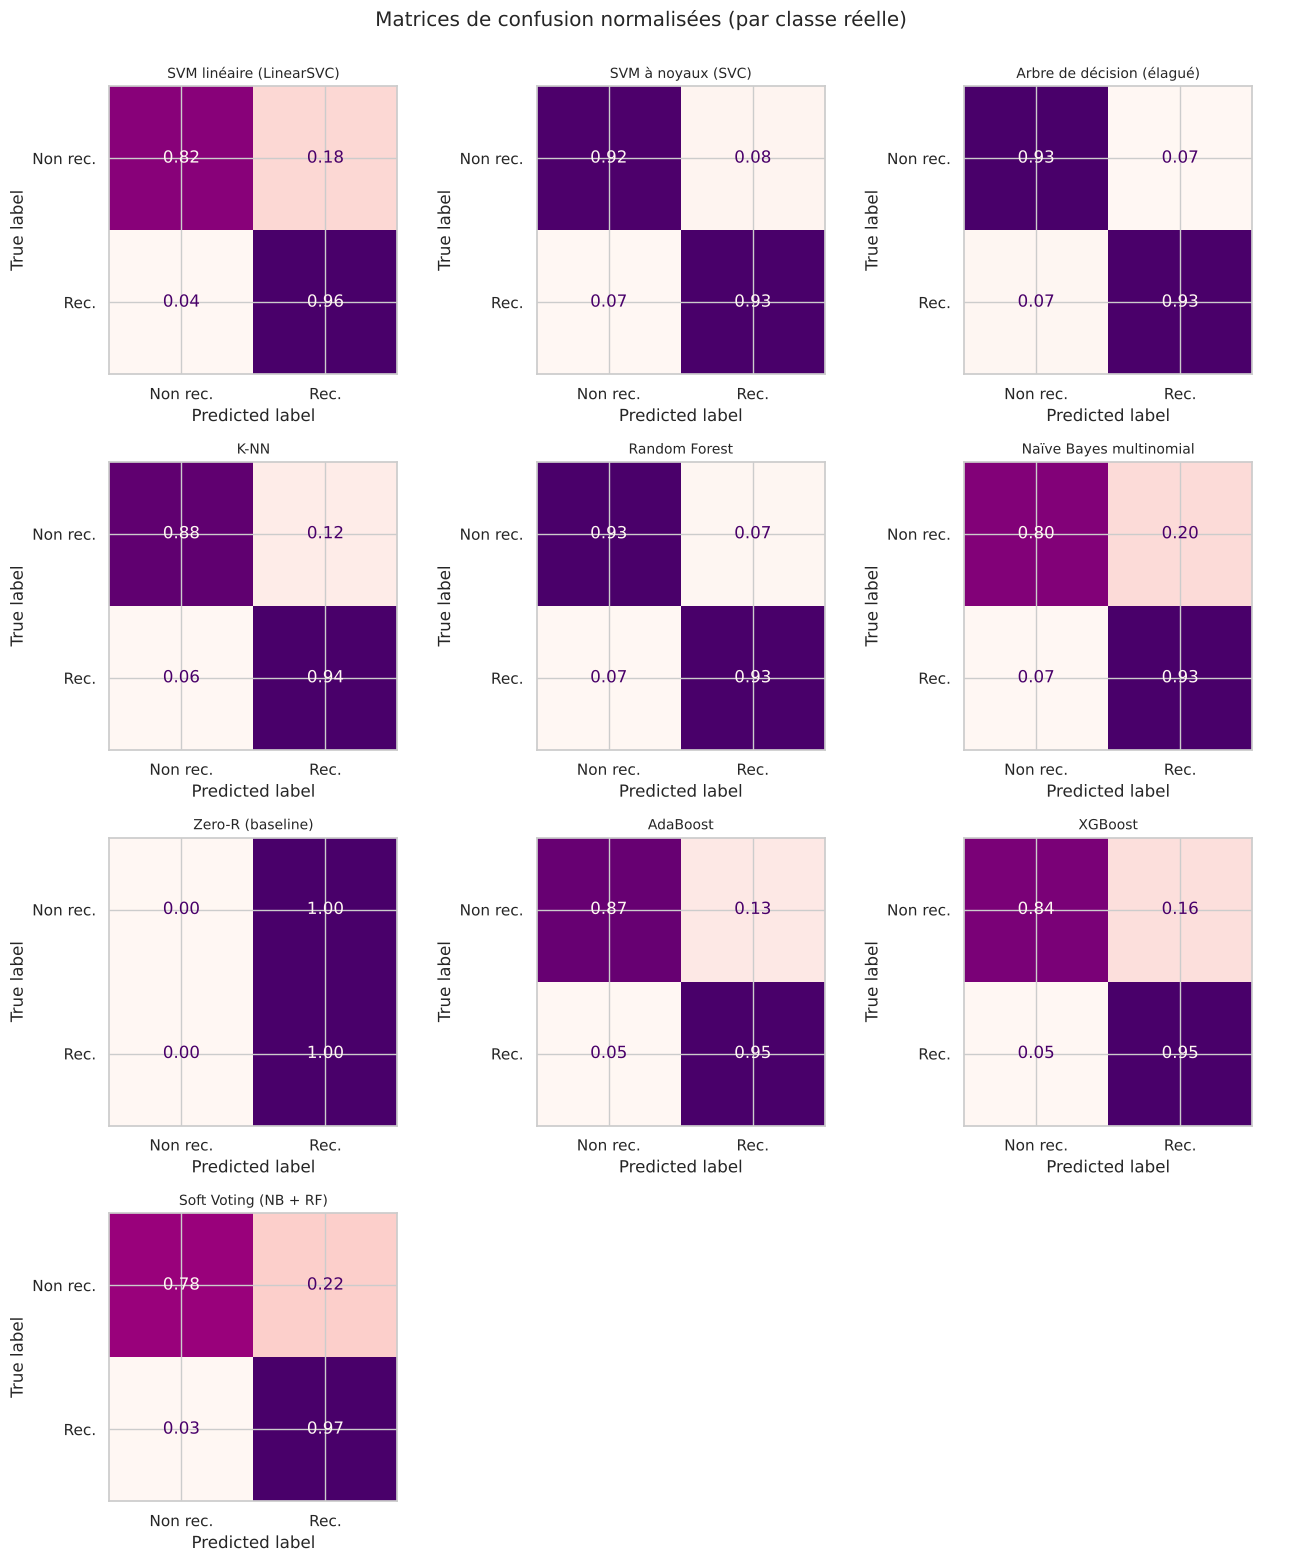

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

names = list(results["Modèle"])
ncols = 3
nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.9 * nrows))
for ax, name in zip(np.ravel(axes), names):
    m = REGISTRY[name]
    ConfusionMatrixDisplay.from_predictions(y_test, m["y_pred"], normalize="true", cmap="RdPu",
                                            display_labels=["Non rec.", "Rec."], ax=ax, colorbar=False, values_format=".2f")
    ax.set_title(name, fontsize=10)
for ax in np.ravel(axes)[len(names):]:
    ax.axis("off")
fig.suptitle("Matrices de confusion normalisées (par classe réelle)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

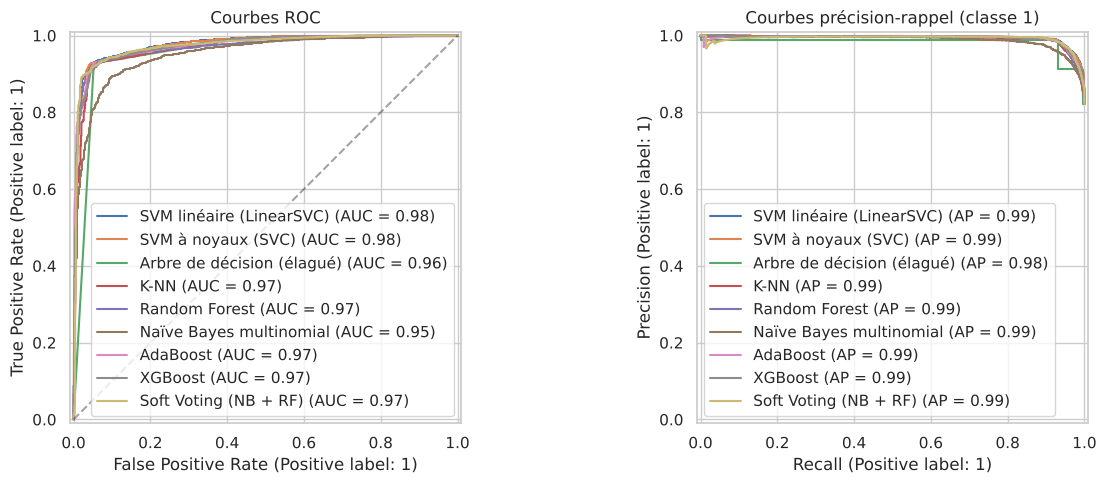

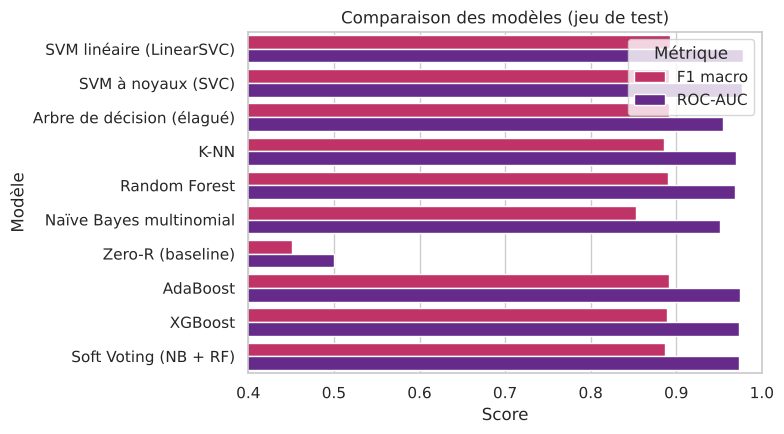

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for name in names:
    if name == "Zero-R (baseline)":
        continue
    s = REGISTRY[name]["scores"]
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=ax2)
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4); ax1.set_title("Courbes ROC")
ax2.set_title("Courbes précision-rappel (classe 1)")
fig.tight_layout(); fig.savefig(FIG_DIR / "roc_pr_curves.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = results.melt(id_vars="Modèle", value_vars=["F1 macro", "ROC-AUC"], var_name="Métrique", value_name="Score")
sns.barplot(data=plot_df, y="Modèle", x="Score", hue="Métrique", palette=["#D81B60", "#6A1B9A"], ax=ax)
ax.set_xlim(0.4, 1.0); ax.set_title("Comparaison des modèles (jeu de test)")
fig.tight_layout(); fig.savefig(FIG_DIR / "model_comparison.png", dpi=200); plt.show()

## 13. Ablation : que se passe-t-il sans `Rating` ou sans texte ?

`Rating` est très lié à la cible (une note de 5 est presque toujours recommandée). On mesure ce que vaut le modèle
**sans** cette variable, avec le texte seul, et avec les métadonnées seules. C'est un point de discussion important pour le rapport :
un F1 élevé peut venir surtout de `Rating`.

Pour que la comparaison soit équitable, le SVM linéaire est **réglé séparément pour chaque variante** (`C` et `class_weight` par validation croisée) :
réutiliser les hyperparamètres du modèle complet pénaliserait injustement les variantes sans `Rating`.

,Variante,Hyperparamètres,CV F1 macro (moy.),CV F1 macro (écart-type),F1 macro (test),F1 (0),ROC-AUC
0,Complet,"{'C': 0.1, 'class_weight': None}",0.9046,0.0056,0.8927,0.8232,0.9774
1,Sans Rating,"{'C': 0.1, 'class_weight': 'balanced'}",0.8373,0.0045,0.8314,0.7291,0.9387
2,Texte seul (Title + Review),"{'C': 0.1, 'class_weight': 'balanced'}",0.8362,0.0035,0.8306,0.7278,0.9397
3,Métadonnées seules (sans texte),"{'C': 0.1, 'class_weight': 'balanced'}",0.9030,0.0056,0.8941,0.8311,0.9717
4,"Métadonnées seules, sans Rating","{'C': 0.1, 'class_weight': 'balanced'}",0.4766,0.0097,0.4780,0.2891,0.5516


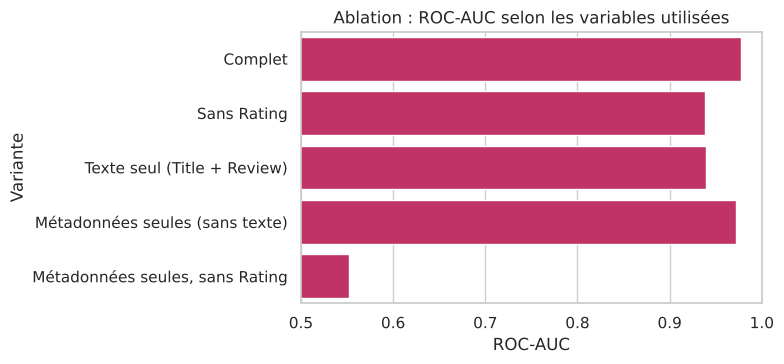

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

variants = {
    "Complet": dict(),
    "Sans Rating": dict(drop_columns=("Rating",)),
    "Texte seul (Title + Review)": dict(use_meta=False),
    "Métadonnées seules (sans texte)": dict(use_text=False),
    "Métadonnées seules, sans Rating": dict(use_text=False, drop_columns=("Rating",)),
}
abl_grid = {"C": [0.1, 1.0] if FAST_MODE else [0.1, 1.0, 10.0], "class_weight": [None, "balanced"]}
rows = []
for label, kw in variants.items():
    p = build_preprocessor("standard", **kw)
    A, B = p.fit_transform(X_train), p.transform(X_test)
    gs = GridSearchCV(LinearSVC(random_state=RANDOM_STATE, max_iter=5000), abl_grid, cv=cv, scoring=SCORING, n_jobs=N_JOBS).fit(A, y_train)
    r = evaluate_model(gs.best_estimator_, B, y_test)
    rows.append({"Variante": label, "Hyperparamètres": str(gs.best_params_),
                 "CV F1 macro (moy.)": gs.best_score_, "CV F1 macro (écart-type)": gs.cv_results_["std_test_score"][gs.best_index_],
                 "F1 macro (test)": r["F1 macro"], "F1 (0)": r["F1 (0)"], "ROC-AUC": r["ROC-AUC"]})
ablation = pd.DataFrame(rows)
ablation.to_csv(REPORT_DIR / "ablation.csv", index=False)
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=ablation, y="Variante", x="ROC-AUC", color="#D81B60", ax=ax)
ax.set_xlim(0.5, 1.0); ax.set_title("Ablation : ROC-AUC selon les variables utilisées")
fig.tight_layout(); fig.savefig(FIG_DIR / "ablation.png", dpi=200); plt.show()

## 14. Importance des variables : SVM linéaire et consensus de plusieurs méthodes

Deux figures : (1) les termes qui poussent vers « recommandé » ou « non recommandé » d'après les coefficients du SVM linéaire ;
(2) une **importance consensus** : on normalise l'importance de chaque variable par son maximum pour chaque méthode (Linear SVC |coefficient|, forêt aléatoire / Gini,
χ², et XGBoost / AdaBoost du notebook 04 lorsque les fichiers existent), puis on classe les variables selon la moyenne. Une variable importante pour toutes les méthodes est plus fiable qu'une variable importante pour une seule.

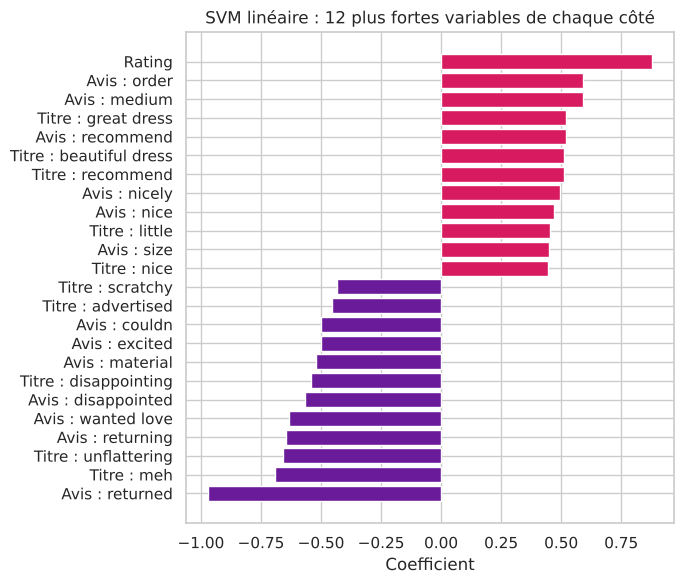

In [ ]:
lin = REGISTRY["SVM linéaire (LinearSVC)"]["model"]
names_f = prep.get_feature_names_out()
pretty = lambda a: pd.Series(a).str.replace("review_tfidf__", "Avis : ").str.replace("title_tfidf__", "Titre : ").str.replace("num__", "").str.replace("cat__", "").values

coef = lin.coef_.ravel()
order = np.argsort(coef)
idx = np.r_[order[:12], order[-12:]]
top = pd.DataFrame({"Variable": pretty(names_f[idx]), "Coefficient": coef[idx]})
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top["Variable"], top["Coefficient"], color=np.where(top["Coefficient"] > 0, "#D81B60", "#6A1B9A"))
ax.set_title("SVM linéaire : 12 plus fortes variables de chaque côté"); ax.set_xlabel("Coefficient")
fig.tight_layout(); fig.savefig(FIG_DIR / "feature_importance.png", dpi=200); plt.show()

,Linear SVC (|coef|),Random Forest (Gini),χ²,XGBoost (gain),AdaBoost,Consensus
Rating,0.905,1.000,1.000,1.0,1.0,0.981
Avis : returned,1.000,0.035,0.080,0.0,0.0,0.223
Titre : unflattering,0.677,0.007,0.155,0.0,0.0,0.168
Titre : meh,0.715,0.001,0.076,0.0,0.0,0.158
Avis : wanted love,0.655,0.032,0.084,0.0,0.0,0.154
Avis : returning,0.665,0.027,0.069,0.0,0.0,0.152
Titre : disappointing,0.558,0.006,0.156,0.0,0.0,0.144
Avis : disappointed,0.584,0.044,0.091,0.0,0.0,0.144
Titre : disappointed,0.421,0.011,0.209,0.0,0.0,0.128
Avis : medium,0.608,0.004,0.003,0.0,0.0,0.123


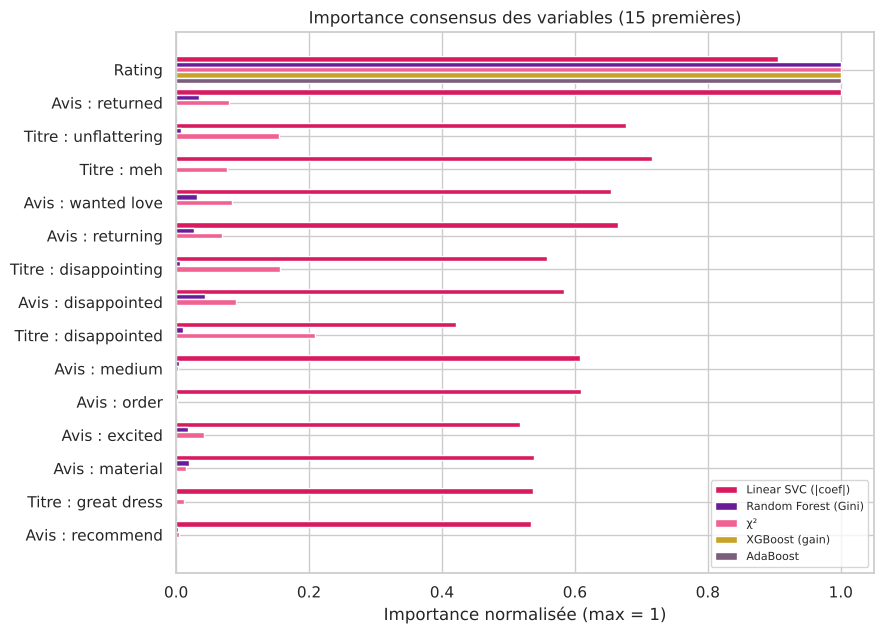

In [ ]:
from sklearn.feature_selection import chi2

imp = {"Linear SVC (|coef|)": np.abs(coef), "Random Forest (Gini)": REGISTRY["Random Forest"]["model"].feature_importances_}
chi_vals, _ = chi2(Xtr_nb, y_train)
imp["χ²"] = np.nan_to_num(chi_vals)
if not FAST_MODE:
    for label, fname in [("XGBoost (gain)", "xgboost_model.pkl"), ("AdaBoost", "adaboost_model.pkl")]:
        if (MODELS_DIR / fname).exists():
            fi = np.asarray(joblib.load(MODELS_DIR / fname).feature_importances_)
            if fi.shape[0] == len(names_f):
                imp[label] = fi

norm = pd.DataFrame({k: v / v.max() for k, v in imp.items()}, index=pretty(names_f))
norm["Consensus"] = norm.mean(axis=1)
consensus = norm.sort_values("Consensus", ascending=False).head(15)
consensus.round(4).to_csv(REPORT_DIR / "feature_importance_consensus.csv", index_label="Variable")
display(consensus.round(3))

methods = [c for c in consensus.columns if c != "Consensus"]
fig, ax = plt.subplots(figsize=(9, 6.5))
y_pos = np.arange(len(consensus)); h = 0.8 / len(methods)
palette = ["#D81B60", "#6A1B9A", "#F06292", "#C9A227", "#7B5E7B"]
for i, m in enumerate(methods):
    ax.barh(y_pos + i * h, consensus[m].values, height=h, label=m, color=palette[i % len(palette)])
ax.set_yticks(y_pos + h * (len(methods) - 1) / 2); ax.set_yticklabels(consensus.index); ax.invert_yaxis()
ax.set_xlabel("Importance normalisée (max = 1)"); ax.set_title("Importance consensus des variables (15 premières)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "importance_consensus.png", dpi=200); plt.show()

## 15. Calibration des probabilités du modèle déployé (Platt)

Le modèle déployé dans l'application est le **Linear SVC du notebook 03** (`models/best_model.pkl`, prétraitement `models/preprocessor.pkl`).
Un SVM fournit une *marge* (distance à l'hyperplan), pas une probabilité : l'application ne peut donc pas afficher de confiance.
On applique la **calibration de Platt** : une régression logistique à une seule variable (la marge) ajustée sur les marges **hors-pli** (validation croisée stratifiée à 6 plis sur le train), ce qui évite d'utiliser le jeu de test.

Ce notebook **n'écrase aucun fichier de l'équipe** : il ajoute seulement `models/platt_calibration.json` (deux nombres, aucun `.pkl` supplémentaire), utilisé par la page « Laboratoire d'avis ». Rien n'est écrit en mode rapide.

,Méthode,Brier,Log-loss
0,Sigmoïde brute de la marge (non calibrée),0.0442,0.1643
1,Platt (marges hors-pli du train),0.0416,0.1390


Platt : P(recommandé) = 1 / (1 + exp(-(3.4791 x marge + 0.0476)))


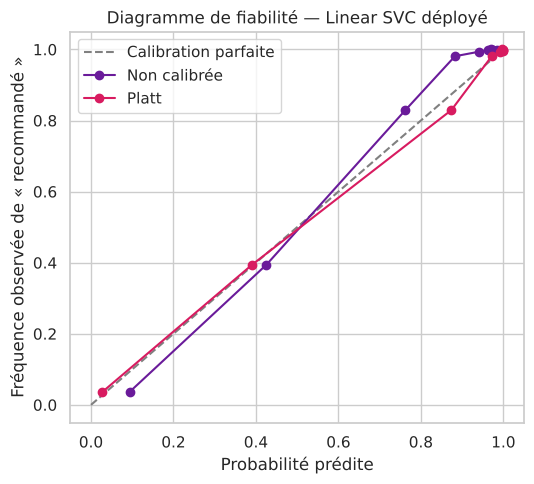

✅ models/platt_calibration.json écrit


In [ ]:
import json
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.model_selection import cross_val_predict

deployed = joblib.load(MODELS_DIR / "best_model.pkl")
deployed_prep = joblib.load(MODELS_DIR / "preprocessor.pkl")
Xtr_dep, Xte_dep = deployed_prep.transform(X_train), deployed_prep.transform(X_test)

# marges hors-pli sur le train -> régression logistique 1-D (Platt)
oof_margin = cross_val_predict(clone(deployed), Xtr_dep, y_train, cv=cv, method="decision_function", n_jobs=N_JOBS)
platt = LogisticRegression(C=1e6, max_iter=1000).fit(oof_margin.reshape(-1, 1), y_train)
coef, intercept = float(platt.coef_[0][0]), float(platt.intercept_[0])

m_test = deployed.decision_function(Xte_dep)
p_platt = 1 / (1 + np.exp(-(coef * m_test + intercept)))
p_naive = 1 / (1 + np.exp(-2.0 * m_test))          # pseudo-probabilité non calibrée
rows = [
    {"Méthode": "Sigmoïde brute de la marge (non calibrée)", "Brier": brier_score_loss(y_test, p_naive), "Log-loss": log_loss(y_test, p_naive)},
    {"Méthode": "Platt (marges hors-pli du train)",          "Brier": brier_score_loss(y_test, p_platt), "Log-loss": log_loss(y_test, p_platt)},
]
calib_table = pd.DataFrame(rows).round(4)
display(calib_table)
print(f"Platt : P(recommandé) = 1 / (1 + exp(-({coef:.4f} x marge + {intercept:.4f})))")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Calibration parfaite")
for lab, p, col in [("Non calibrée", p_naive, "#6A1B9A"), ("Platt", p_platt, "#D81B60")]:
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, "o-", color=col, label=lab)
ax.set_xlabel("Probabilité prédite"); ax.set_ylabel("Fréquence observée de « recommandé »")
ax.set_title("Diagramme de fiabilité — Linear SVC déployé"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "calibration_curve.png", dpi=200); plt.show()
calib_table.to_csv(REPORT_DIR / "calibration.csv", index=False)

if FAST_MODE:
    print("Mode rapide : aucun fichier écrit dans models/.")
else:
    (MODELS_DIR / "platt_calibration.json").write_text(json.dumps({
        "model": type(deployed).__name__,
        "method": "Platt scaling sur marges hors-pli (StratifiedKFold 6, random_state=42)",
        "coef": coef, "intercept": intercept,
        "brier_test": float(brier_score_loss(y_test, p_platt)),
    }, indent=2))
    print("✅ models/platt_calibration.json écrit")